In [1]:
from pathlib import Path
from collections import Counter
import shutil
import yaml
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd
import random

DATASET = Path(
    "~/UltraCNN/data/kitti/tracking"
).expanduser()

IMAGE_DIR = DATASET / "data_tracking_image_2/training/image_02"
LABEL_DIR = DATASET / "data_tracking_label_2/training/label_02"

OUTPUT_DIR = DATASET / "yolo_dataset_v1"

PROJECT_DIR = Path("~/UltraCNN").expanduser()
RUNS_DIR = PROJECT_DIR / "runs" / "detect"

train_sequences = [f"{i:04d}" for i in range(1, 17)]
val_sequences = [f"{i:04d}" for i in range(17, 21)]
test_sequences = ["0000"]

CLASS_MAP = {
    "Car": 0,
    "Van": 0,
    "Truck": 1,
    "Pedestrian": 2,
    "Cyclist": 3,
}

CLASS_NAMES = [
    "car",
    "truck",
    "pedestrian",
    "cyclist"
]

print("Dataset:", DATASET)
print("Output:", OUTPUT_DIR)
print("Training sequences:", len(train_sequences))
print("Validation sequences:", len(val_sequences))
print("Test sequences:", test_sequences)
print("Classes:", CLASS_NAMES)

Dataset: /home/ghost/UltraCNN/data/kitti/tracking
Output: /home/ghost/UltraCNN/data/kitti/tracking/yolo_dataset_v1
Training sequences: 16
Validation sequences: 4
Test sequences: ['0000']
Classes: ['car', 'truck', 'pedestrian', 'cyclist']


In [2]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    raise RuntimeError("CUDA GPU not detected. Stop before training.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce GTX 1650
GPU memory: 3.63 GB


In [3]:
import os

# Create a fresh output directory.
# This only affects yolo_dataset_v1.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

for split in ["train", "val"]:
    (OUTPUT_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

SPLITS = {
    "train": train_sequences,
    "val": val_sequences
}

stats = {
    split: Counter()
    for split in SPLITS
}

for split, sequences in SPLITS.items():

    image_output = OUTPUT_DIR / "images" / split
    label_output = OUTPUT_DIR / "labels" / split

    print(f"\nProcessing {split.upper()}")

    for seq in sequences:

        label_file = LABEL_DIR / f"{seq}.txt"
        image_folder = IMAGE_DIR / seq

        assert label_file.exists(), label_file
        assert image_folder.exists(), image_folder

        annotations = {}

        # Read KITTI annotations.
        with open(label_file) as f:

            for line in f:

                fields = line.strip().split()

                if len(fields) != 17:
                    continue

                frame_id = int(fields[0])
                class_name = fields[2]

                if class_name not in CLASS_MAP:
                    continue

                annotations.setdefault(
                    frame_id, []
                ).append(fields)

        for image_path in sorted(image_folder.glob("*.png")):

            frame_id = int(image_path.stem)

            image = cv2.imread(str(image_path))

            if image is None:
                continue

            height, width = image.shape[:2]

            filename = f"{seq}_{frame_id:06d}"

            # Link original image instead of copying it.
            destination_image = (
                image_output / f"{filename}.png"
            )

            destination_image.symlink_to(
                image_path.resolve()
            )

            yolo_labels = []

            for fields in annotations.get(frame_id, []):

                class_name = fields[2]
                class_id = CLASS_MAP[class_name]

                x1, y1, x2, y2 = map(
                    float, fields[6:10]
                )

                # Clip bounding boxes to image boundaries.
                x1 = np.clip(x1, 0, width)
                x2 = np.clip(x2, 0, width)
                y1 = np.clip(y1, 0, height)
                y2 = np.clip(y2, 0, height)

                box_width = x2 - x1
                box_height = y2 - y1

                if box_width <= 0 or box_height <= 0:
                    continue

                x_center = ((x1 + x2) / 2) / width
                y_center = ((y1 + y2) / 2) / height

                norm_width = box_width / width
                norm_height = box_height / height

                yolo_labels.append(
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{norm_width:.6f} "
                    f"{norm_height:.6f}"
                )

                stats[split][class_name] += 1

            label_path = (
                label_output / f"{filename}.txt"
            )

            with open(label_path, "w") as f:
                f.write("\n".join(yolo_labels))

            stats[split]["images"] += 1

    print(f"Completed {split}")

print("\nDATASET CONVERSION SUMMARY")

for split, counts in stats.items():
    print(f"\n{split.upper()}")
    print(dict(counts))


Processing TRAIN
Completed train

Processing VAL
Completed val

DATASET CONVERSION SUMMARY

TRAIN
{'Car': 19279, 'images': 5474, 'Van': 1702, 'Pedestrian': 4578, 'Truck': 1044, 'Cyclist': 1375}

VAL
{'Pedestrian': 6870, 'Cyclist': 409, 'images': 2380, 'Car': 7778, 'Van': 1307, 'Truck': 145}


In [4]:
data_yaml = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {
        i: name
        for i, name in enumerate(CLASS_NAMES)
    }
}

yaml_path = OUTPUT_DIR / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(
        data_yaml,
        f,
        sort_keys=False
    )

print(yaml_path.read_text())

path: /home/ghost/UltraCNN/data/kitti/tracking/yolo_dataset_v1
train: images/train
val: images/val
names:
  0: car
  1: truck
  2: pedestrian
  3: cyclist



In [5]:
for split, expected in [
    ("train", 5474),
    ("val", 2380)
]:

    image_files = list(
        (OUTPUT_DIR / "images" / split).glob("*.png")
    )

    label_files = list(
        (OUTPUT_DIR / "labels" / split).glob("*.txt")
    )

    print(f"\n{split.upper()}")
    print("Images:", len(image_files))
    print("Labels:", len(label_files))

    assert len(image_files) == expected
    assert len(label_files) == expected

    for label_file in random.sample(label_files, min(100, len(label_files))):

        for line in label_file.read_text().splitlines():

            values = line.split()

            assert len(values) == 5

            class_id, xc, yc, w, h = map(float, values)

            assert class_id in range(4)
            assert 0 <= xc <= 1
            assert 0 <= yc <= 1
            assert 0 < w <= 1
            assert 0 < h <= 1

print("\nDataset verification passed.")


TRAIN
Images: 5474
Labels: 5474

VAL
Images: 2380
Labels: 2380

Dataset verification passed.


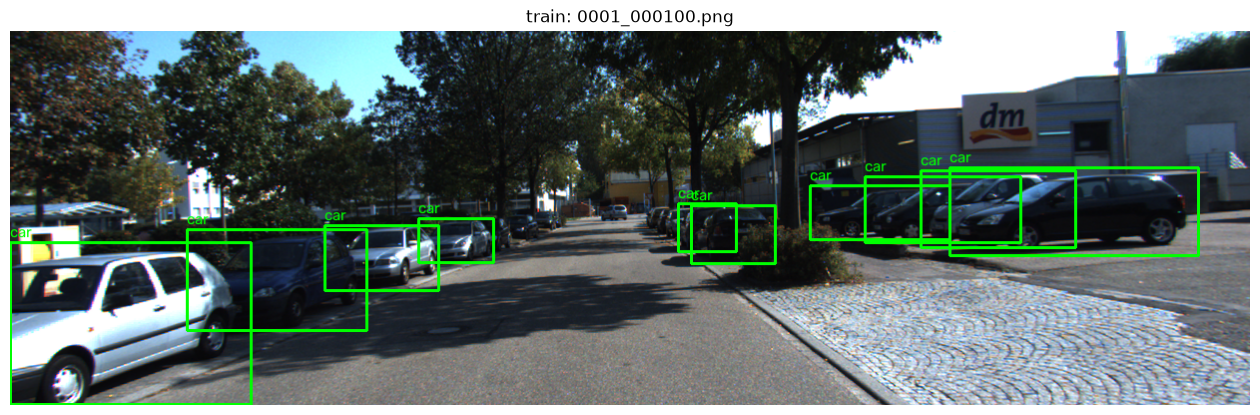

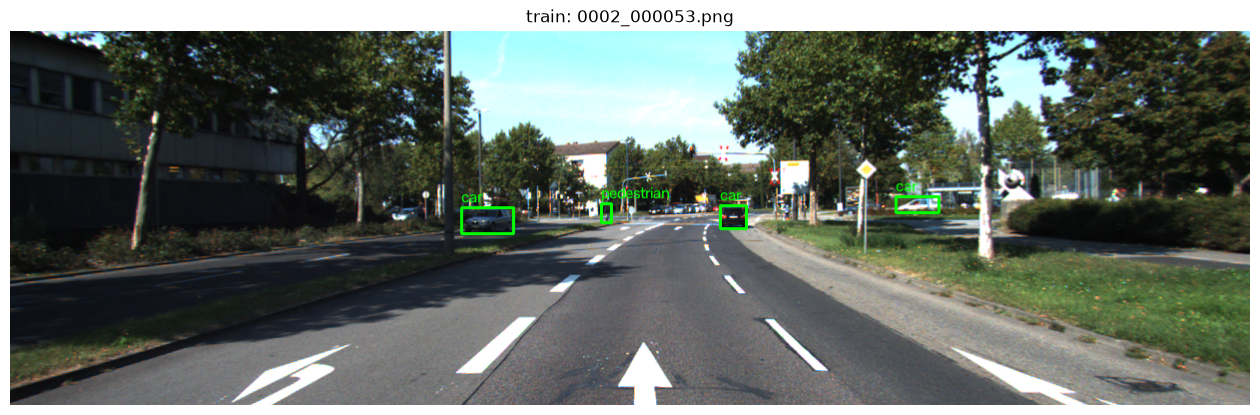

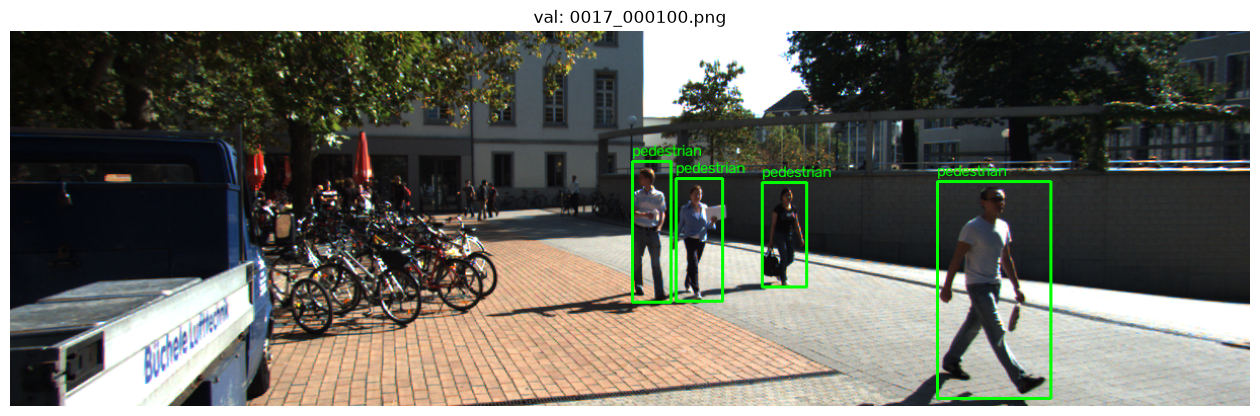

In [6]:
def show_yolo_sample(split="train", index=0):

    image_dir = OUTPUT_DIR / "images" / split
    label_dir = OUTPUT_DIR / "labels" / split

    image_files = sorted(image_dir.glob("*.png"))

    image_path = image_files[index]
    label_path = label_dir / f"{image_path.stem}.txt"

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    for line in label_path.read_text().splitlines():

        values = list(map(float, line.split()))

        class_id = int(values[0])
        xc, yc, bw, bh = values[1:]

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            CLASS_NAMES[class_id],
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1
        )

    plt.figure(figsize=(16, 8))
    plt.imshow(image)
    plt.title(f"{split}: {image_path.name}")
    plt.axis("off")
    plt.show()


show_yolo_sample("train", 100)
show_yolo_sample("train", 500)
show_yolo_sample("val", 100)

In [7]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("Loaded pretrained YOLO11n")

Loaded pretrained YOLO11n


In [8]:
results = model.train(

    # Dataset
    data=str(yaml_path),

    # Training configuration
    epochs=30,
    imgsz=640,
    batch=4,

    # GPU
    device=0,
    workers=2,

    # Optimization
    optimizer="auto",
    lr0=0.001,
    weight_decay=0.0005,

    # Augmentation
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,

    degrees=0.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,

    mosaic=1.0,
    close_mosaic=10,

    # Training control
    patience=10,
    amp=True,
    cache=False,

    # Output
    project=str(RUNS_DIR),
    name="kitti_yolo11n",
    exist_ok=False,

    plots=True,
    save=True,
    verbose=True
)

New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.184 🚀 Python-3.12.3 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce GTX 1650, 3716MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/ghost/UltraCNN/data/kitti/tracking/yolo_dataset_v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300